# Missingness

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
OUTPUTS = PROJECT_ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

In [3]:
from src.data import load_ett, chronological_split, scale

train, test = chronological_split(load_ett())
df, _, _ = scale(train=train, test=test)

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.missingness import simulate_missingness
from src.figures_cfg import apply_theme, INK

apply_theme()

In [5]:
mechanisms = ["mar", "mcar", "mnar"]
proportions = [10, 30, 50]

---

## Proportions

In [6]:
proportion_dict = {}

for mech in mechanisms:

    proportion_dict[mech] = {}

    for prop in proportions:

        X, _ = simulate_missingness(df=df, mechanism=mech, n=prop, random_seed=1)

        proportion_dict[mech][prop] = X.isna().sum().sum() / df.size

proportion_results = pd.DataFrame(proportion_dict)

True proportions (with seed 1) for each mechanism.

In [7]:
proportion_results

,mar,mcar,mnar
10,0.099991,0.099991,0.099991
30,0.299995,0.299995,0.299995
50,0.500000,0.500000,0.500000


Exactly the same number within each proportion, error only due to rounding.

## Distributions

### Compare distributions of masked and true values

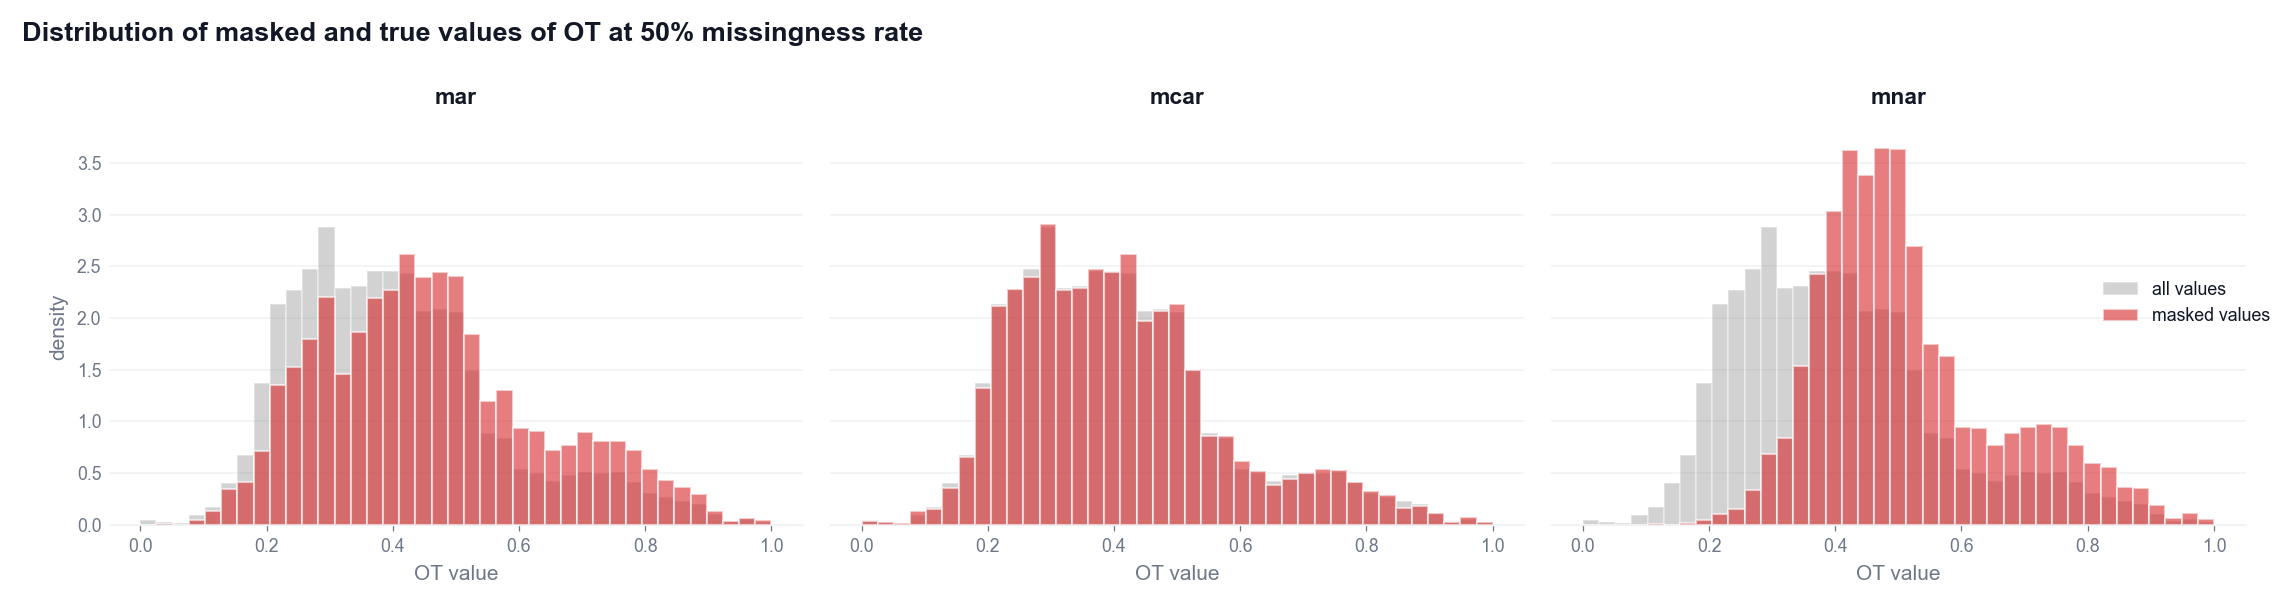

In [23]:
TARGET = "OT"
PROPORTION = 50
SEED = 1

full = df[TARGET]
bins = np.linspace(full.min(), full.max(), 40)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, mech in zip(axes, mechanisms):
    gappy, mask = simulate_missingness(df, mech, PROPORTION, SEED)
    mask_col = mask[TARGET]
    masked_true_vals = full[mask_col]

    ax.hist(full, bins=bins, density=True, alpha=0.35,
            color="grey", label="all values")
    ax.hist(masked_true_vals, bins=bins, density=True, alpha=0.6,
            color="tab:red", label="masked values")
    ax.set_title(mech)
    ax.set_xlabel(f"{TARGET} value")

axes[0].set_ylabel("density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right")
plt.suptitle(f"Distribution of masked and true values of {TARGET} at {PROPORTION}% missingness rate",
             x=0.0, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

fig.savefig(OUTPUTS / "figures/amputation/ot_masked_distribution_50_mr.png")

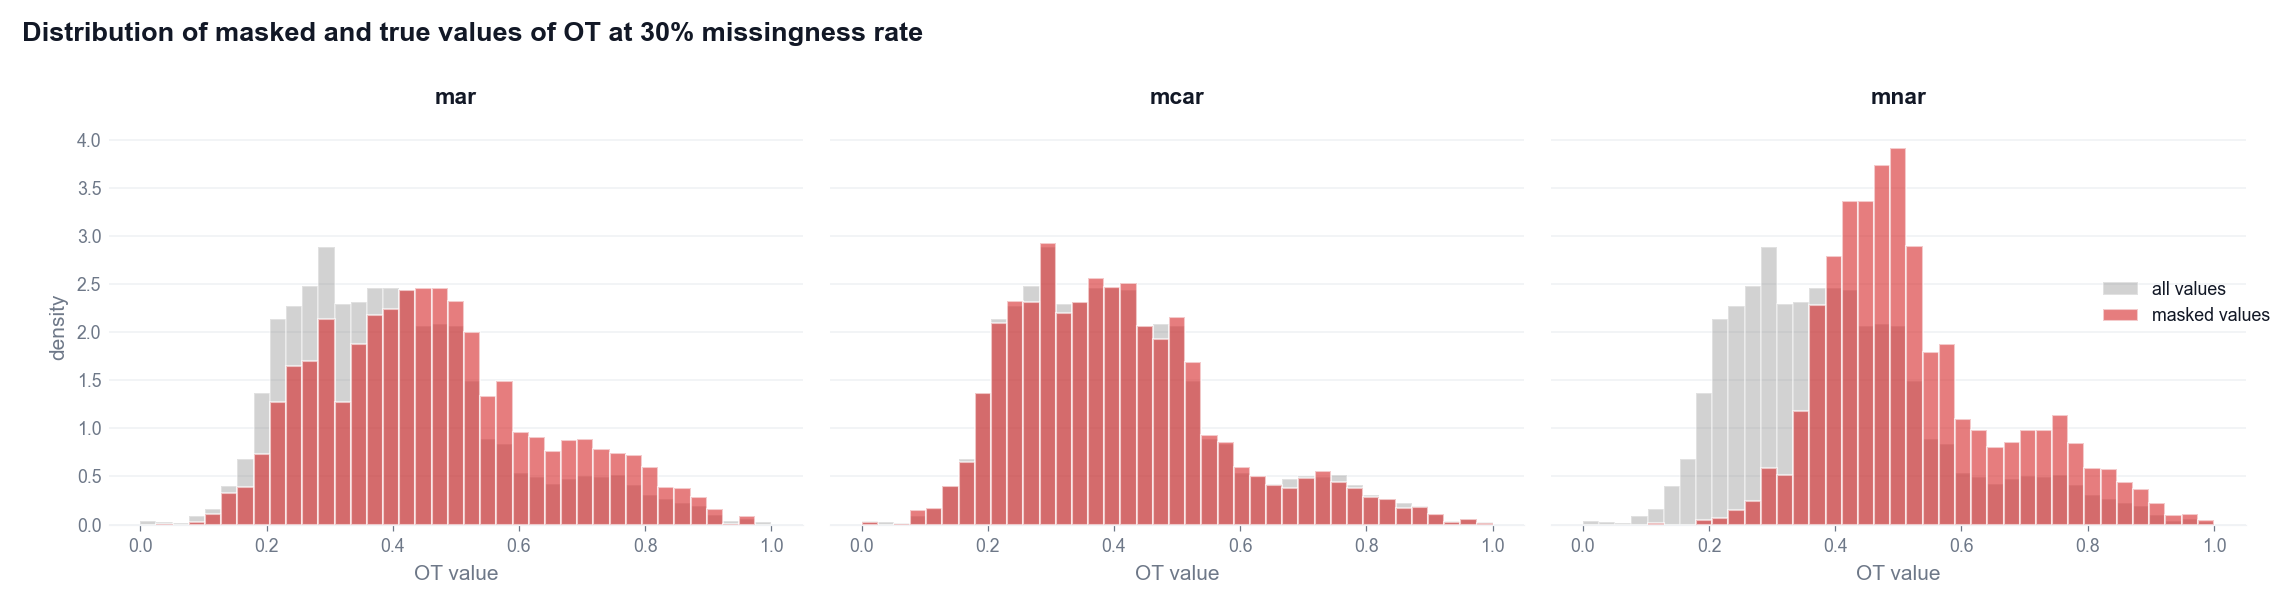

In [22]:
TARGET = "OT"
PROPORTION = 30
SEED = 1

full = df[TARGET]
bins = np.linspace(full.min(), full.max(), 40)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, mech in zip(axes, mechanisms):
    gappy, mask = simulate_missingness(df, mech, PROPORTION, SEED)
    mask_col = mask[TARGET]
    masked_true_vals = full[mask_col]

    ax.hist(full, bins=bins, density=True, alpha=0.35,
            color="grey", label="all values")
    ax.hist(masked_true_vals, bins=bins, density=True, alpha=0.6,
            color="tab:red", label="masked values")
    ax.set_title(mech)
    ax.set_xlabel(f"{TARGET} value")

axes[0].set_ylabel("density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right")
plt.suptitle(f"Distribution of masked and true values of {TARGET} at {PROPORTION}% missingness rate",
             x=0.0, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

fig.savefig(OUTPUTS / "figures/amputation/ot_masked_distribution_30_mr.png")


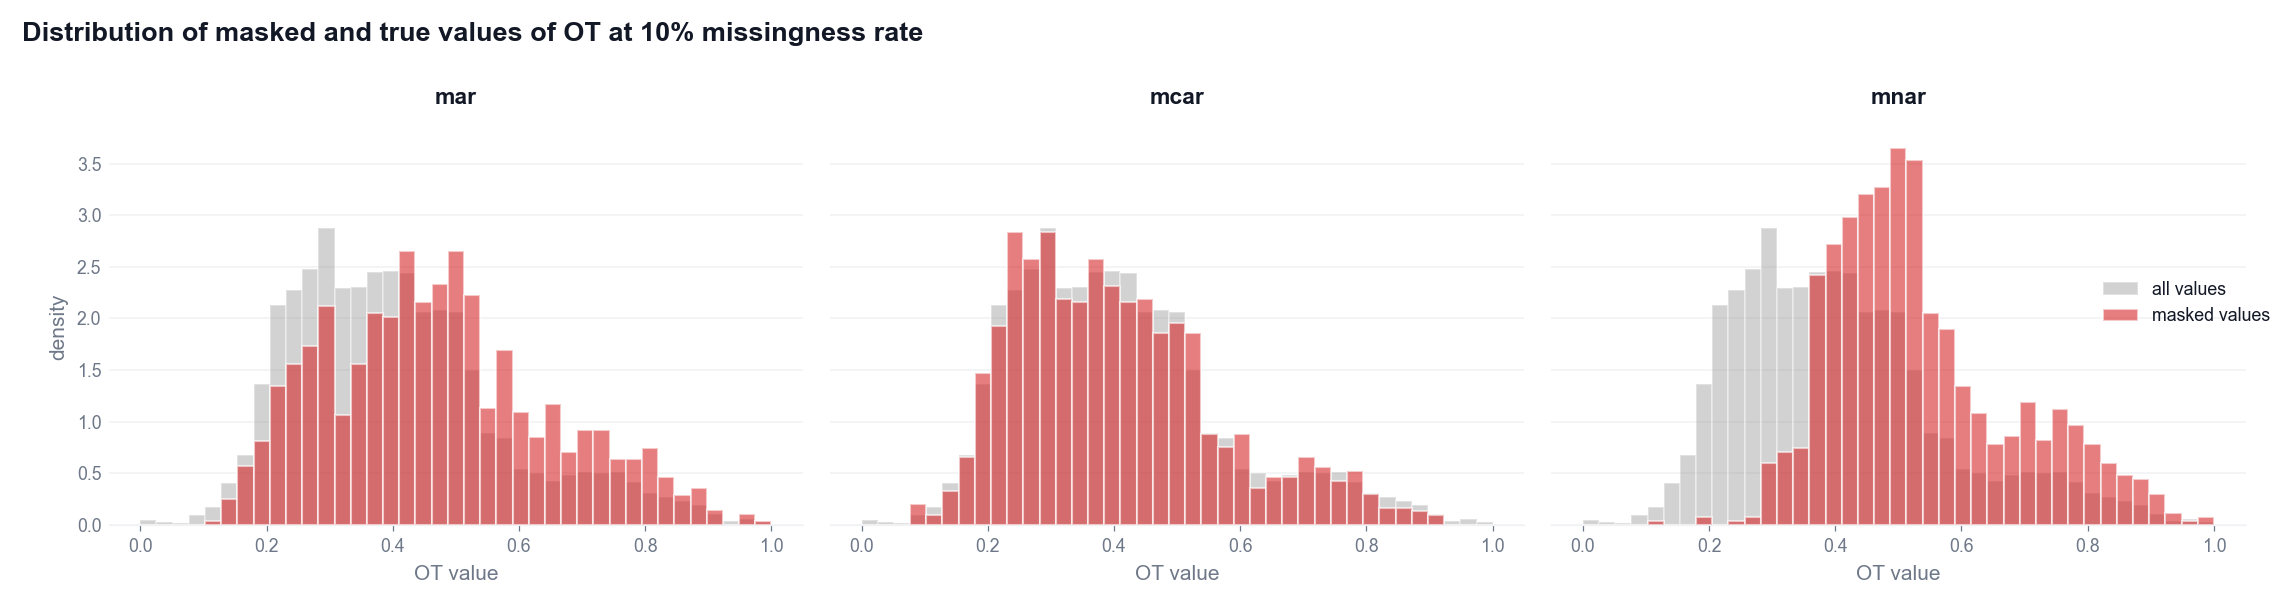

In [21]:
TARGET = "OT"
PROPORTION = 10
SEED = 1

full = df[TARGET]
bins = np.linspace(full.min(), full.max(), 40)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, mech in zip(axes, mechanisms):
    gappy, mask = simulate_missingness(df, mech, PROPORTION, SEED)
    mask_col = mask[TARGET]
    masked_true_vals = full[mask_col]

    ax.hist(full, bins=bins, density=True, alpha=0.35,
            color="grey", label="all values")
    ax.hist(masked_true_vals, bins=bins, density=True, alpha=0.6,
            color="tab:red", label="masked values")
    ax.set_title(mech)
    ax.set_xlabel(f"{TARGET} value")

axes[0].set_ylabel("density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right")
plt.suptitle(f"Distribution of masked and true values of {TARGET} at {PROPORTION}% missingness rate",
             x=0.0, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

fig.savefig(OUTPUTS / "figures/amputation/ot_masked_distribution_10_mr.png")

MCAR preserves distribution.

MAR

In [9]:
df.columns

Index(['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT'], dtype='str')

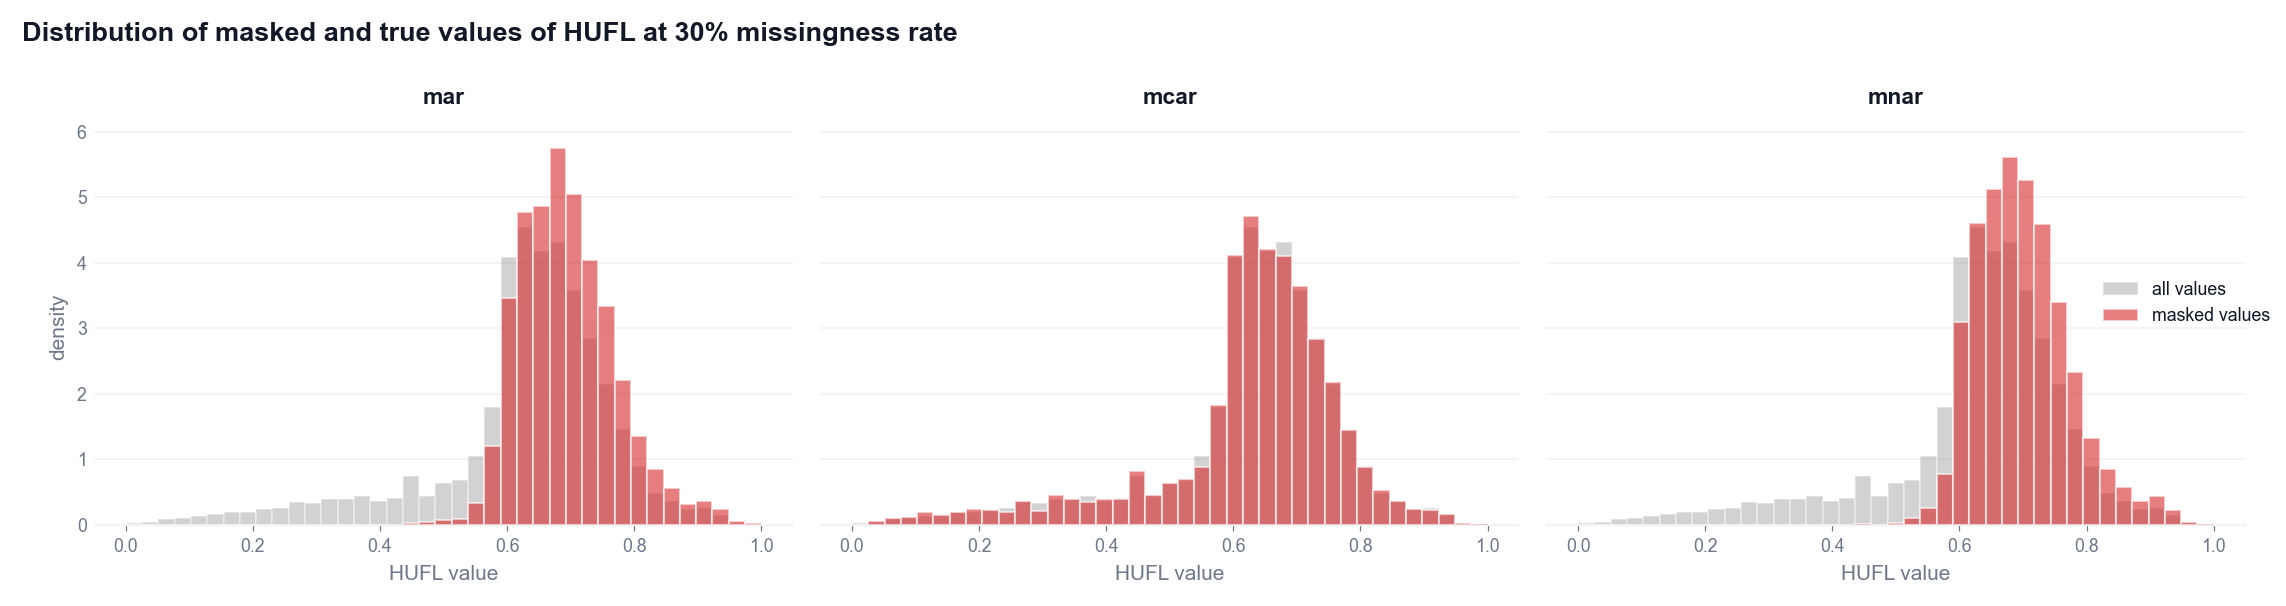

In [29]:
TARGET = "HUFL"
PROPORTION = 30
SEED = 1

full = df[TARGET]
bins = np.linspace(full.min(), full.max(), 40)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, mech in zip(axes, mechanisms):
    gappy, mask = simulate_missingness(df, mech, PROPORTION, SEED)
    mask_col = mask[TARGET]
    masked_true_vals = full[mask_col]

    ax.hist(full, bins=bins, density=True, alpha=0.35,
            color="grey", label="all values")
    ax.hist(masked_true_vals, bins=bins, density=True, alpha=0.6,
            color="tab:red", label="masked values")
    ax.set_title(mech)
    ax.set_xlabel(f"{TARGET} value")

axes[0].set_ylabel("density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right")
plt.suptitle(f"Distribution of masked and true values of {TARGET} at {PROPORTION}% missingness rate",
             x=0.0, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

fig.savefig(OUTPUTS / "figures/amputation/hufl_masked_distribution_30_mr.png")

### Compare distributions of MAR with driver column

C:\Users\stuwi\AppData\Local\Temp\ipykernel_7848\2150416253.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(); fig.tight_layout(); plt.show()


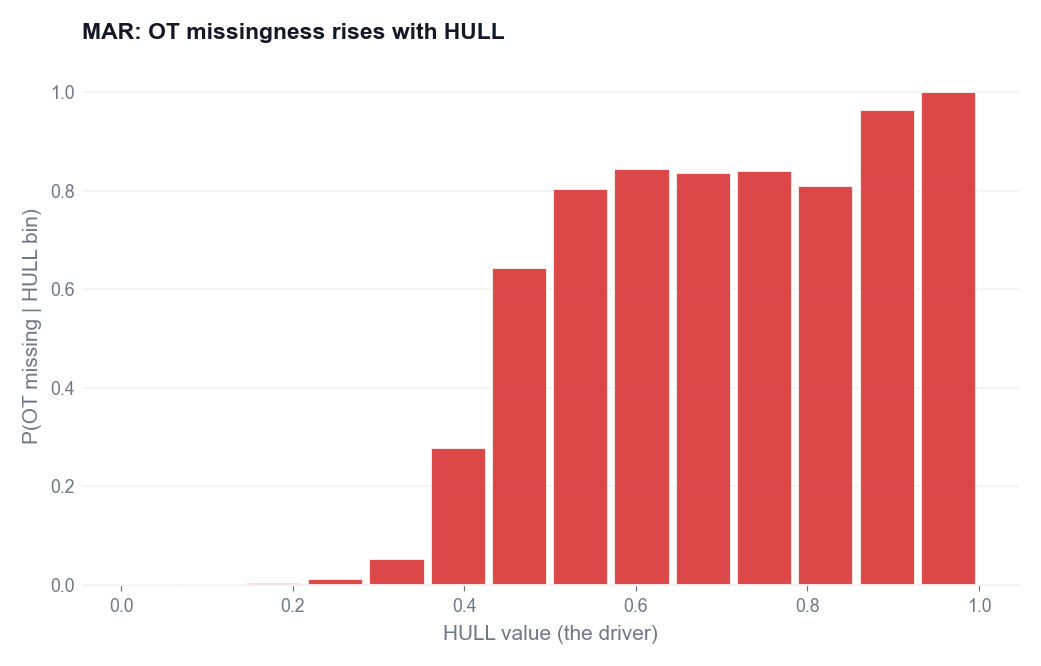

In [18]:
import numpy as np
import matplotlib.pyplot as plt

driver = df.corr()["OT"].drop("OT").abs().idxmax()
gappy, mask = simulate_missingness(df, "mar", 50, 1)

driver_vals = df[driver].to_numpy()
ot_missing = mask["OT"].to_numpy().astype(float)

bins = np.linspace(driver_vals.min(), driver_vals.max(), 15)
idx = np.digitize(driver_vals, bins)
rate = [ot_missing[idx == b].mean() for b in range(1, len(bins))]
centers = (bins[:-1] + bins[1:]) / 2

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(centers, rate, width=(bins[1]-bins[0])*0.9, color="tab:red", alpha=0.85)
# ax.axhline(0.5, color="grey", ls="--", lw=1, label="overall rate (50%)")
ax.set_xlabel(f"{driver} value (the driver)")
ax.set_ylabel(f"P(OT missing | {driver} bin)")   # makes the conditioning explicit
ax.set_title(f"MAR: OT missingness rises with {driver}", color=INK,
             fontweight="bold", fontsize=11, loc="left", pad=14)
ax.legend(); fig.tight_layout(); plt.show()

fig.savefig(OUTPUTS / "figures/amputation/ot_hull_driver_missingness_probability.png")

C:\Users\stuwi\AppData\Local\Temp\ipykernel_7848\622972950.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(); fig.tight_layout(); plt.show()


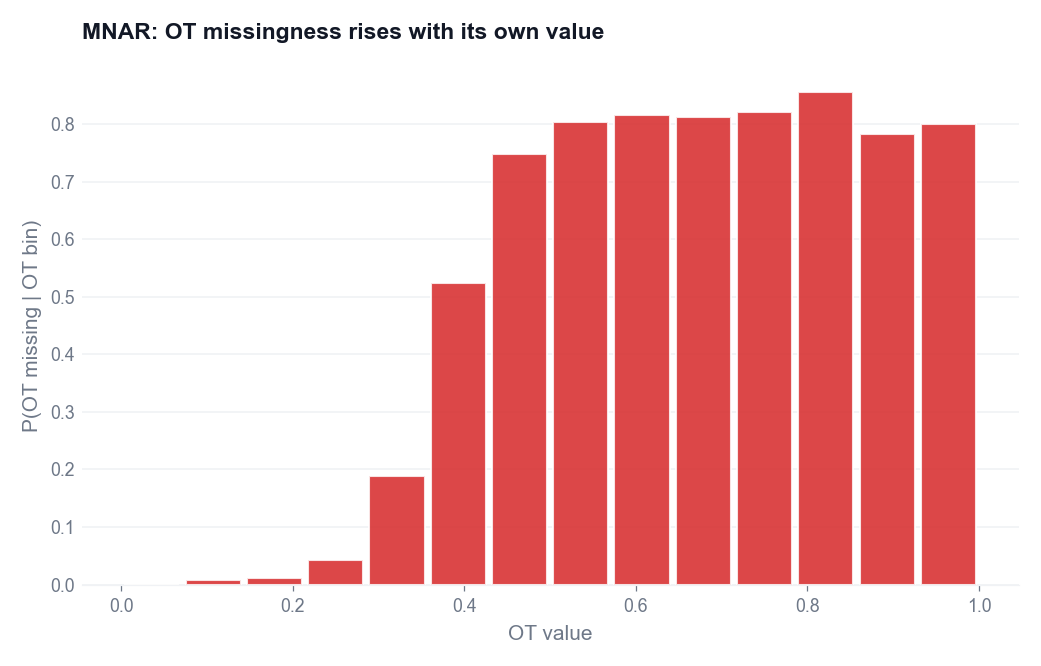

In [26]:
import numpy as np
import matplotlib.pyplot as plt

gappy, mask = simulate_missingness(df, "mnar", 50, 1)

ot_vals = df["OT"].to_numpy()                  # condition on OT's own value
ot_missing = mask["OT"].to_numpy().astype(float)

bins = np.linspace(ot_vals.min(), ot_vals.max(), 15)
idx = np.digitize(ot_vals, bins)
rate = [ot_missing[idx == b].mean() for b in range(1, len(bins))]
centers = (bins[:-1] + bins[1:]) / 2



fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(centers, rate, width=(bins[1]-bins[0])*0.9, color="tab:red", alpha=0.85)

ax.set_xlabel("OT value")
ax.set_ylabel("P(OT missing | OT bin)")         # conditioning on OT itself
ax.set_title("MNAR: OT missingness rises with its own value", color=INK,
             fontweight="bold", fontsize=11, loc="left", pad=14)
ax.legend(); fig.tight_layout(); plt.show()

fig.savefig(OUTPUTS / "figures/amputation/ot_mnar_missingness_probability.png")